Loading dataset...
Selected Indicator for visualization: Dietary energy supply used in the estimation of the prevalence of undernourishment (kcal/cap/day)
Chart saved successfully as 'world_food_security_trend.png'!


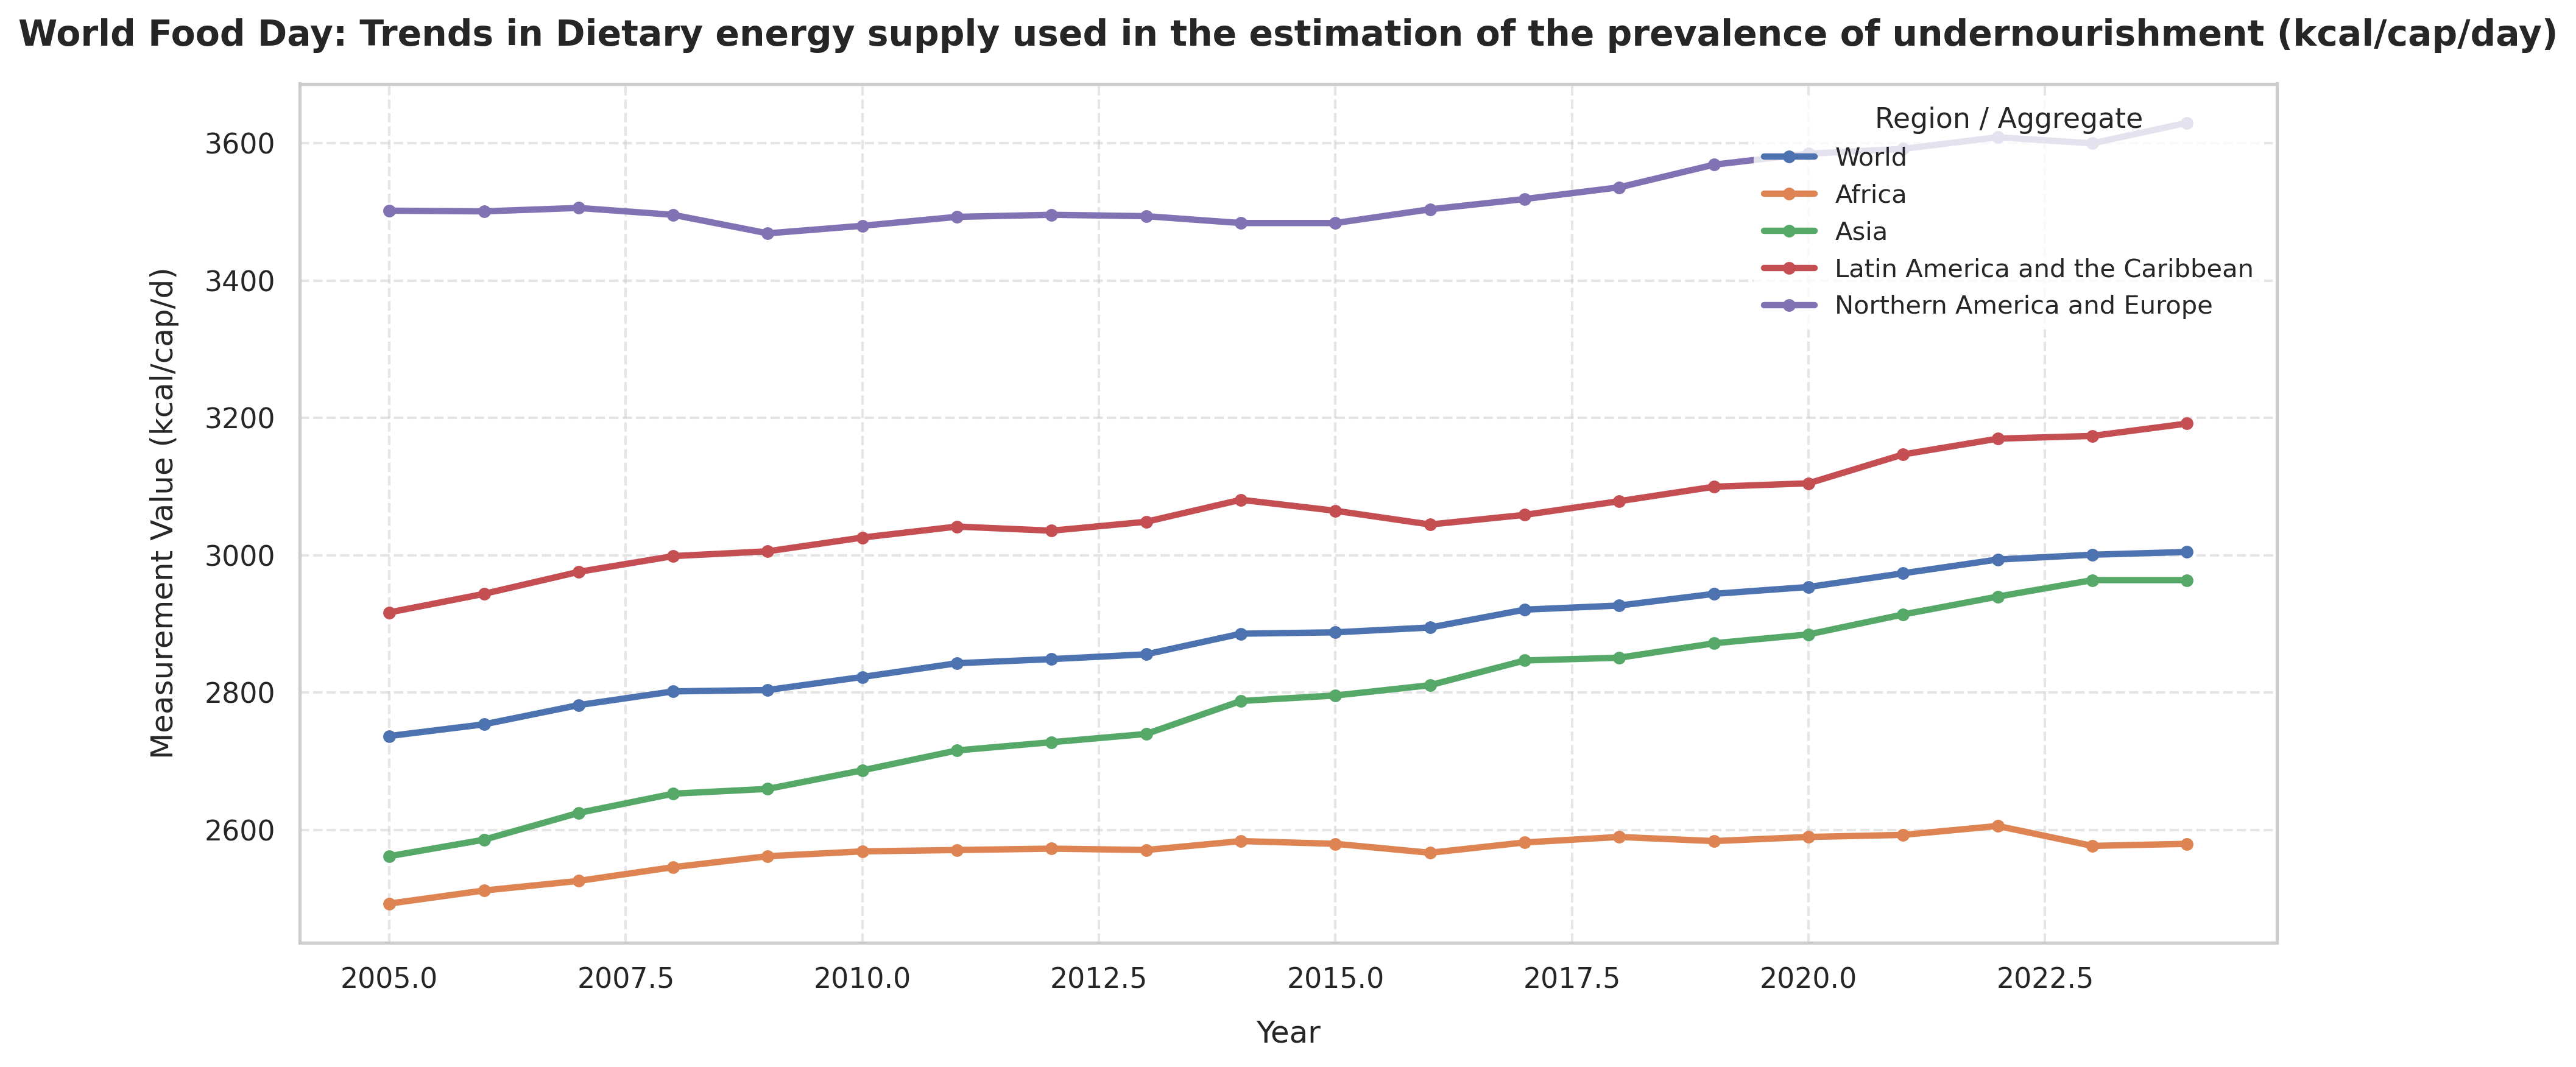

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Load the dataset directly from GitHub
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-10-14/food_security.csv"
print("Loading dataset...")
df = pd.read_csv(url)

# 2. Select a key indicator (looking for undernourishment or food insecurity first)
target_item = None
for item in df["Item"].unique():
  if any(
      keyword in item.lower()
      for keyword in ["undernourishment", "food insecurity"]
  ):
    target_item = item
    break

# Fallback to the first available item if keywords aren't found
if not target_item:
  target_item = df["Item"].unique()[0]

print(f"Selected Indicator for visualization: {target_item}")

# 3. Filter for major world regions / aggregates
preferred_regions = [
    "World",
    "Africa",
    "Asia",
    "Latin America and the Caribbean",
    "Northern America and Europe",
]
available_regions = [r for r in preferred_regions if r in df["Area"].values]

# Fallback if specific regions aren't in the subset
if not available_regions:
  available_regions = df["Area"].value_counts().head(4).index.tolist()

# Filter dataframe
sub_df = df[
    (df["Item"] == target_item)
    & (df["Area"].isin(available_regions))
    & (df["Year_Start"] >= 2005)
].copy()

sub_df = sub_df.sort_values(by="Year_Start")

# 4. Create a clean, professional plot
# Set visual style
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(12, 6), dpi=300)

palette = sns.color_palette("deep", len(available_regions))

for i, region in enumerate(available_regions):
  region_data = sub_df[sub_df["Area"] == region]
  if region_data.empty:
    continue

  # Plot the main trend line
  ax.plot(
      region_data["Year_Start"],
      region_data["Value"],
      label=region,
      linewidth=2.5,
      color=palette[i],
      marker="o",
      markersize=4,
  )

  # Plot confidence intervals as a shaded region (if available)
  if (
      "CI_Lower" in region_data.columns
      and "CI_Upper" in region_data.columns
      and not region_data["CI_Lower"].isna().all()
  ):
    ax.fill_between(
        region_data["Year_Start"],
        region_data["CI_Lower"],
        region_data["CI_Upper"],
        color=palette[i],
        alpha=0.15,
        edgecolor="none",
    )

# 5. Formatting labels, title, and legend
unit = (
    sub_df["Unit"].iloc[0]
    if not sub_df.empty and pd.notna(sub_df["Unit"].iloc[0])
    else ""
)
ax.set_title(
    f"World Food Day: Trends in {target_item}",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel("Year", fontsize=12, labelpad=10)
ax.set_ylabel(
    f"Measurement Value ({unit})" if unit else "Value",
    fontsize=12,
    labelpad=10,
)

# Customize legend and grid
ax.legend(
    title="Region / Aggregate",
    frameon=True,
    facecolor="white",
    edgecolor="none",
    fontsize=10,
    title_fontsize=11,
)
ax.grid(True, linestyle="--", alpha=0.5)

# Save high-resolution image and show
plt.tight_layout()
plt.savefig("world_food_security_trend.png", dpi=300)
print("Chart saved successfully as 'world_food_security_trend.png'!")
plt.show()